In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [8]:
db = pd.read_csv('lifeInsurance.csv', delimiter=';')
db

,Gender,Age,MaritalStatus,NumberOfChildren,PhysicalStatus,ChronicDisease,MonthlySalary,Decision
0,0.0,80.0,1.0,1.0,1.0,0.0,2611.4159,0.0
1,0.0,101.0,1.0,3.0,1.0,1.0,3132.2018,1.0
2,0.0,34.0,1.0,3.0,1.0,1.0,2462.3115,1.0
3,0.0,34.0,0.0,1.0,1.0,1.0,3051.9166,0.0
4,0.0,93.0,1.0,2.0,1.0,1.0,2401.4440,1.0
...,...,...,...,...,...,...,...,...
595,1.0,34.0,1.0,1.0,2.0,1.0,3744.5544,0.0
596,0.0,45.0,1.0,1.0,0.0,1.0,1796.9875,1.0
597,0.0,37.0,0.0,3.0,1.0,0.0,2107.5915,0.0
598,1.0,73.0,0.0,2.0,1.0,2.0,2325.4465,1.0


### Insurance Company Suggestion

Rule to decide whether to have life insurance or not based on the criterias defined

In [ ]:
age_points = [
    (30, 5), (40, 10), (50, 15), ('inf', 20)
]

health_points = {
    0: 15, 
    1: 10, 
    2: 5
}

finance_points = [
    (1700, 15), (3500, 10), ('inf', 5)
]

family_points = [
    (0, 5), (1, 10), ('inf', 15)
]

def calculate_points(row):
    age = row['Age']
    health = row['ChronicDisease']
    finance = row['MonthlySalary']
    family = row['NumberOfChildren']

    # Calculate points based on age
    for limit, points in age_points:
        if limit == 'inf' or age <= limit:
            age_score = points
            break

    # Calculate points based on health
    health_score = health_points[health]

    # Calculate points based on finance
    for limit, points in finance_points:
        if limit == 'inf' or finance <= limit:
            finance_score = points
            break

    # Calculate points based on family
    for limit, points in family_points:
        if limit == 'inf' or family <= limit:
            family_score = points
            break

    return age_score + health_score + finance_score + family_score

# Add column suggestion, 1 for points higher than 50, 0 otherwise
db['Suggestion'] = db.apply(calculate_points, axis=1)
# Create a new column 'suggestion' based on the points
db['Suggestion'] = np.where(db['Suggestion'] > 50, 1, 0)
db

,Gender,Age,MaritalStatus,NumberOfChildren,PhysicalStatus,ChronicDisease,MonthlySalary,Decision,Suggestion
0,0.0,80.0,1.0,1.0,1.0,0.0,2611.4159,0.0,1
1,0.0,101.0,1.0,3.0,1.0,1.0,3132.2018,1.0,1
2,0.0,34.0,1.0,3.0,1.0,1.0,2462.3115,1.0,0
3,0.0,34.0,0.0,1.0,1.0,1.0,3051.9166,0.0,0
4,0.0,93.0,1.0,2.0,1.0,1.0,2401.4440,1.0,1
...,...,...,...,...,...,...,...,...,...
595,1.0,34.0,1.0,1.0,2.0,1.0,3744.5544,0.0,0
596,0.0,45.0,1.0,1.0,0.0,1.0,1796.9875,1.0,0
597,0.0,37.0,0.0,3.0,1.0,0.0,2107.5915,0.0,0
598,1.0,73.0,0.0,2.0,1.0,2.0,2325.4465,1.0,0


### Discretization process for Age and Monthly Salary

We decided to divide the age to 5 categories based on our data (and based on the life insurance rules):
- 18-29 -> Young Adult (0)
- 30–39 -> Adult (1)
- 40–49 -> Mature Adult (2)
- 50-59 -> Middle Aged (3)
- 60+ -> Senior (4)

And monthly salary were separated for the following ranges:
- <1499 -> Low Income (0)
- 1501-2999 -> Mid Income (1)
- 3000+ High Income (2)

In [ ]:
# Discretization of the Age column
def discretize_age(age):
    if age < 30:
        return 0
    elif 30 <= age < 39:
        return 1
    elif 40 <= age < 49:
        return 2
    elif 50 <= age < 59:
        return 3
    else:
        return 4

def discretize_salary(salary):
    if salary < 1500:
        return 0
    elif 1500 <= salary < 3000:
        return 1
    else:
        return 2

# Apply discretization to the Age and MonthlySalary columns
db['Age'] = db['Age'].apply(discretize_age)
db['MonthlySalary'] = db['MonthlySalary'].apply(discretize_salary)
print(db['Age'].value_counts())
print(db['MonthlySalary' ].value_counts())

Age
4    332
1    130
2     81
3     57
Name: count, dtype: int64
MonthlySalary
1    373
2    198
0     29
Name: count, dtype: int64


### Bayesian Model

In [11]:
class BayesianModel:
    def __init__(self):
        self.prior_prob = None
        self.conditional_probs = {
            "Gender": {},
            "Age": {},
            "MaritalStatus": {},
            "NumberOfChildren": {},
            "PhysicalStatus": {},
            "ChronicDisease": {},
            "MonthlySalary": {},
            "Suggestion": {}
        }

    # Calculate prior probabilities for each class
    def priori_cal(self, y):
        _, counts = np.unique(y, return_counts=True)
        return counts / len(y), counts

    def calculate_condition(self, X, y, categories, prior_counts, name):
        C_n = prior_counts[0]
        C_y = prior_counts[1]

        for category in categories:
            # obtain index of values where X[X == category] is True
            indices = np.where(X == category)[0]

            # obtain the values of y at those indices
            y_values = y.iloc[indices]

            X_n = np.sum(y_values == 0)
            X_y = np.sum(y_values == 1)

            # Find how many values we have for each feature, if any is 0, we apply laplace correction
            X_count = X.value_counts()
            if len(categories) > len(X_count):
                # print("Applying Laplace correction.")
                X_n += 1
                X_y += 1
                C_n += len(categories)
                C_y += len(categories)

            # calculate the likelihood for feature given y
            likelihood_n = X_n / C_n
            likelihood_y = X_y / C_y

            self.conditional_probs[name][category] = (likelihood_n, likelihood_y)

    def calculate_likelihood(self, X):
        likelihood_n = 1
        likelihood_y = 1

        likelihood_n *= self.conditional_probs["Gender"][X.iloc[0]][0]
        likelihood_y *= self.conditional_probs["Gender"][X.iloc[0]][1]

        likelihood_n *= self.conditional_probs["Age"][X.iloc[1]][0]
        likelihood_y *= self.conditional_probs["Age"][X.iloc[1]][1]

        likelihood_n *= self.conditional_probs["MaritalStatus"][X.iloc[2]][0]
        likelihood_y *= self.conditional_probs["MaritalStatus"][X.iloc[2]][1]

        likelihood_n *= self.conditional_probs["NumberOfChildren"][X.iloc[3]][0]
        likelihood_y *= self.conditional_probs["NumberOfChildren"][X.iloc[3]][1]

        likelihood_n *= self.conditional_probs["PhysicalStatus"][X.iloc[4]][0]
        likelihood_y *= self.conditional_probs["PhysicalStatus"][X.iloc[4]][1]

        likelihood_n *= self.conditional_probs["ChronicDisease"][X.iloc[5]][0]
        likelihood_y *= self.conditional_probs['ChronicDisease'][X.iloc[5]][1]

        likelihood_n *= self.conditional_probs["MonthlySalary"][X.iloc[6]][0]
        likelihood_y *= self.conditional_probs['MonthlySalary'][X.iloc[6]][1]

        likelihood_n *= self.conditional_probs["Suggestion"][X.iloc[7]][0]
        likelihood_y *= self.conditional_probs['Suggestion'][X.iloc[7]][1]

        return likelihood_n, likelihood_y
    
    def print_probabilities(self):
        print("Prior Probabilities:")
        print(self.prior_prob)
        print("\nConditional Probabilities:")
        for feature, probs in self.conditional_probs.items():
            print(f"{feature}:")
            for category, (p_n, p_y) in probs.items():
                print(f"  {category}: P(0) = {p_n:.4f}, P(1) = {p_y:.4f}")

    def train(self, X, y):
        self.prior_prob, self.prior_counts = self.priori_cal(y)

        self.calculate_condition(X["Gender"], y, [0, 1], self.prior_counts, "Gender")
        self.calculate_condition(X["Age"], y, [0, 1, 2, 3, 4], self.prior_counts, "Age")
        self.calculate_condition(X["MaritalStatus"], y, [0, 1], self.prior_counts, "MaritalStatus")
        self.calculate_condition(X["NumberOfChildren"], y, [0, 1, 2, 3], self.prior_counts, "NumberOfChildren")
        self.calculate_condition(X["PhysicalStatus"], y, [0, 1, 2], self.prior_counts, "PhysicalStatus")
        self.calculate_condition(X["ChronicDisease"], y, [0, 1, 2], self.prior_counts, "ChronicDisease")
        self.calculate_condition(X["MonthlySalary"], y, [0, 1, 2], self.prior_counts, "MonthlySalary")
        self.calculate_condition(X["Suggestion"], y, [0, 1], self.prior_counts, "Suggestion")

    def predict(self, X):
        prob_0, prob_1 = self.calculate_likelihood(X)
        return (prob_1 / (prob_0 + prob_1)) >= 0.5 

### Model Evaluation

In [31]:
X = db.drop(columns=["Decision"])
y = db["Decision"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)


model = BayesianModel()
model.train(X_train, y_train)

# Predicting on the test set
predictions = []
for i in range(len(X_test)):
    prediction = model.predict(X_test.iloc[i])
    predictions.append(prediction)

# Print accuracy
accuracy = np.mean(predictions == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

# Print the conditional probabilities
model.print_probabilities()

Accuracy: 83.33%
Prior Probabilities:
[0.68333333 0.31666667]

Conditional Probabilities:
Gender:
  0: P(0) = 0.8726, P(1) = 0.8012
  1: P(0) = 0.1274, P(1) = 0.1988
Age:
  0: P(0) = 0.0027, P(1) = 0.0057
  1: P(0) = 0.2586, P(1) = 0.1105
  2: P(0) = 0.1406, P(1) = 0.1022
  3: P(0) = 0.1131, P(1) = 0.0471
  4: P(0) = 0.4492, P(1) = 0.6480
MaritalStatus:
  0: P(0) = 0.5285, P(1) = 0.3743
  1: P(0) = 0.4715, P(1) = 0.6257
NumberOfChildren:
  0: P(0) = 0.2981, P(1) = 0.1579
  1: P(0) = 0.2791, P(1) = 0.1930
  2: P(0) = 0.2276, P(1) = 0.2632
  3: P(0) = 0.1951, P(1) = 0.3860
PhysicalStatus:
  0: P(0) = 0.1978, P(1) = 0.4386
  1: P(0) = 0.5501, P(1) = 0.5146
  2: P(0) = 0.2520, P(1) = 0.0468
ChronicDisease:
  0: P(0) = 0.6260, P(1) = 0.2105
  1: P(0) = 0.3306, P(1) = 0.6901
  2: P(0) = 0.0434, P(1) = 0.0994
MonthlySalary:
  0: P(0) = 0.0407, P(1) = 0.0643
  1: P(0) = 0.5393, P(1) = 0.8304
  2: P(0) = 0.4201, P(1) = 0.1053
Suggestion:
  0: P(0) = 0.6287, P(1) = 0.5263
  1: P(0) = 0.3713, P(1

### Test on a lot of different types of splits

C:\Users\emanu\AppData\Local\Temp\ipykernel_22196\739711983.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


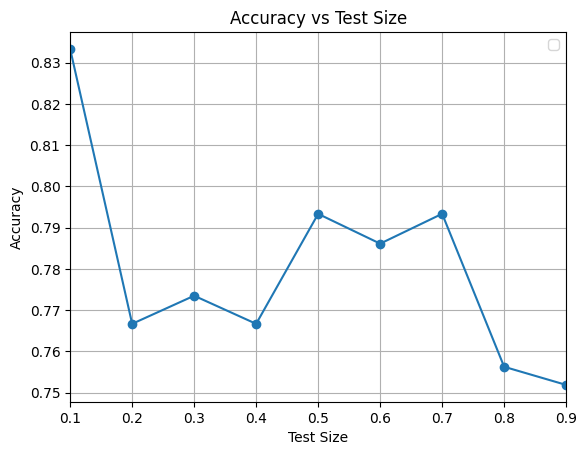

In [ ]:
def plot_accuracy_split(X, y, test_size=0.1):
    accuracies = []
    test_sizes = np.arange(0.1, 1.0, 0.1)

    for size in test_sizes:
        model = BayesianModel()
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=size, random_state=42)
        model.train(X_train, y_train)
        
        predictions = []
        for i in range(len(X_test)):
            prediction = model.predict(X_test.iloc[i])
            predictions.append(prediction)

        accuracy = np.mean(predictions == y_test)
        accuracies.append(accuracy)

    plt.plot(test_sizes, accuracies, marker='o')
    plt.title('Accuracy vs Test Size')
    plt.xlabel('Test Size')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.xticks(test_sizes)
    plt.xlim(0.1, 0.9)
    plt.grid()
    plt.show()

plot_accuracy_split(X, y)
